# 03 — Modelagem

**Objetivo.** Treinar e comparar diferentes algoritmos de classificação e escolher o que
melhor separa bons e maus pagadores, com um protocolo de validação que não se engane.

**Roteiro.**
1. Separar 20% dos **clientes** para o teste final (intocado até o notebook 04).
2. Medir o que acontece quando o split ignora que a mesma pessoa tem várias contas.
3. Definir cinco famílias de modelo mais uma linha de base.
4. Comparar tudo por validação cruzada repetida, em dois conjuntos de atributos.
5. Ajustar hiperparâmetros dos três melhores.
6. Escolher o modelo, definir o limiar de decisão e treinar a versão final.

Todo o código reutilizável está em `src/models.py` e `src/evaluation.py`.

In [1]:
import json
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))   # permite `from src... import ...`

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from src.config import (COR_BOM, COR_MAU, COR_NEUTRA, CV_FOLDS, CV_REPEATS, FEATURE_SETS, GROUP,
                        METRICS, MODELS)
from src.data import load_processed
from src.evaluation import best_threshold, policy_table, score
from src.models import (PARAM_GRIDS, choose_model, cross_validate_model, cv_splits, get_models,
                        split_train_test, tune)
from src.plots import save, set_style

# Semente fixa: usada em TODO ponto com aleatoriedade (split, modelos, CV).
RANDOM_STATE = 42

RAW = Path("..") / "data" / "raw"
PROCESSED = Path("..") / "data" / "processed"
TARGET = "MAU_PAGADOR"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
set_style()

In [2]:
df = load_processed()
print(df.shape, "| maus:", df[TARGET].sum(), f"({df[TARGET].mean():.2%})")
for nome, cols in FEATURE_SETS.items():
    print(f"{nome}: {len(cols)} atributos")

(24566, 32) | maus: 370 (1.51%)
cadastro: 19 atributos
cadastro_historico: 26 atributos


Dois conjuntos de atributos serão comparados:
- **`cadastro`** (19 atributos): só a ficha cadastral. Vale para qualquer solicitante.
- **`cadastro_historico`** (26 atributos): ficha mais o comportamento do mesmo cliente em
  contas anteriores ao pedido.

## 1. Split treino/teste

O hold-out é **estratificado** (mesma proporção de maus nos dois lados) e **agrupado por
cliente**: todas as contas de uma pessoa ficam no treino ou no teste, nunca divididas. É um
dos cinco folds de um `StratifiedGroupKFold`, o que dá 20% para teste.

In [3]:
train, test = split_train_test(df, random_state=RANDOM_STATE)
resumo = pd.DataFrame({
    "contas": [len(train), len(test)],
    "clientes": [train[GROUP].nunique(), test[GROUP].nunique()],
    "maus": [train[TARGET].sum(), test[TARGET].sum()],
    "% maus": [100 * train[TARGET].mean(), 100 * test[TARGET].mean()],
}, index=["treino", "teste"])
print("Clientes presentes nos dois conjuntos:", len(set(train[GROUP]) & set(test[GROUP])))
resumo.round(2)

Clientes presentes nos dois conjuntos: 0


,contas,clientes,maus,% maus
treino,19652,6370,296,1.51
teste,4914,1576,74,1.51


**Leitura.** Treino com 19.652 contas de 6.370 clientes e 296 maus; teste com 4.914 contas de
1.576 clientes e 74 maus. A taxa de maus é a mesma nos dois (1,51%) e nenhum cliente aparece
dos dois lados. O teste só volta a ser usado no notebook 04, uma única vez.

Com 74 maus no teste, qualquer métrica medida nele tem margem de erro larga. Por isso a
escolha do modelo é feita por validação cruzada repetida no treino, e o teste serve como
conferência final, com intervalo de confiança.

## 2. Por que agrupar por cliente: o vazamento medido

A EDA mostrou que cada cliente tem, em média, 3,7 contas com ficha cadastral idêntica. Um
`train_test_split` ou `KFold` comum espalha essas contas entre treino e validação. O modelo
então reencontra, na validação, fichas que já viu no treino, e basta lembrar o rótulo.

O experimento abaixo mede o efeito com o mesmo modelo (Random Forest, só ficha cadastral) e
os mesmos dados, mudando apenas a forma de montar os folds.

In [4]:
feats_cad = FEATURE_SETS["cadastro"]
rf_cad = get_models(feats_cad)["random_forest"]
y_train = train[TARGET].to_numpy()

folds_agrupados = [(tr, va) for _, _, tr, va in cv_splits(train, repeats=1, random_state=RANDOM_STATE)]
folds_aleatorios = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
rf_decora = clone(rf_cad).set_params(clf__min_samples_leaf=1)   # árvores profundas: decoram fichas

vazamento = []
for rotulo, modelo in [("Random Forest (folhas ≥ 20 contas)", rf_cad),
                       ("Random Forest (árvores sem limite)", rf_decora)]:
    linha = {"modelo": rotulo}
    for nome_cv, cv in [("folds aleatórios", folds_aleatorios), ("folds por cliente", folds_agrupados)]:
        p = cross_val_predict(modelo, train[feats_cad], y_train, cv=cv, method="predict_proba")[:, 1]
        linha[f"AUC — {nome_cv}"] = roc_auc_score(y_train, p)
    vazamento.append(linha)
vazamento = pd.DataFrame(vazamento).set_index("modelo")
vazamento["inflação"] = vazamento["AUC — folds aleatórios"] - vazamento["AUC — folds por cliente"]
vazamento.to_csv(METRICS / "vazamento_split_aleatorio.csv")
vazamento.round(3)

,AUC — folds aleatórios,AUC — folds por cliente,inflação
modelo,,,
Random Forest (folhas ≥ 20 contas),0.759,0.596,0.163
Random Forest (árvores sem limite),0.818,0.598,0.221


**Leitura.** Com folds aleatórios o modelo parece razoável (AUC 0,76) e, se as árvores
puderem crescer sem limite, parece bom (0,82). Com folds por cliente, os dois caem para
**0,60**. A diferença de 0,16 a 0,22 ponto de AUC não é capacidade de prever: é memória. A
floresta sem limite de profundidade é a que mais "melhora" justamente porque é a que mais
decora.

É o motivo pelo qual resultados muito altos são comuns nesta base pública: split aleatório
com clientes repetidos (e, muitas vezes, oversampling aplicado antes do split) produz
números que não se sustentam em clientes novos. **Todos os resultados deste projeto usam
folds agrupados por cliente.**

## 3. Modelos candidatos

Cinco famílias de algoritmo, cada uma com uma lógica diferente, mais uma linha de base:

| Modelo | Por que está na lista |
|---|---|
| `baseline` | prevê a taxa média para todos; é o piso (AUC 0,50) que qualquer modelo precisa superar |
| `logistic_regression` | padrão do mercado de crédito; linear e interpretável por coeficientes |
| `knn` | decide pela vizinhança; não supõe forma funcional |
| `decision_tree` | regras legíveis; captura interações e não linearidades simples |
| `random_forest` | média de centenas de árvores; robusto a ruído e a atributos irrelevantes |
| `gradient_boosting` | árvores em sequência corrigindo o erro anterior (`HistGradientBoostingClassifier`, o equivalente do scikit-learn ao LightGBM) |

**Pipeline.** Cada modelo é um `Pipeline` de pré-processamento mais classificador. One-hot
com agrupamento de categorias raras (menos de 1% do treino) para todos; log e
`StandardScaler` para logística e KNN. Como tudo está dentro do pipeline, é reajustado em
cada fold só com os dados de treino.

**Desbalanceamento.** Com 65 bons para cada mau, um modelo sem correção aprende a dizer "bom"
para todos. Os classificadores usam `class_weight="balanced"`: cada mau pesa cerca de 65
vezes mais na função de perda. O efeito é o de um oversampling, sem registros sintéticos
(SMOTE interpola entre vizinhos, o que não faz sentido para variáveis categóricas em one-hot)
e sem o risco de duplicar linhas antes do split. O KNN não aceita pesos de classe; nele o
desbalanceamento é tratado só na escolha do limiar.

In [5]:
pd.set_option("display.max_colwidth", None)
pd.DataFrame([
    {"modelo": nome,
     "pré-processamento": "log + padronização + one-hot" if "scaler" in str(m[0]) else "one-hot",
     "classificador": " ".join(str(m[-1]).split())}
    for nome, m in get_models(FEATURE_SETS["cadastro_historico"]).items()
]).set_index("modelo")

,pré-processamento,classificador
modelo,,
baseline,one-hot,DummyClassifier()
logistic_regression,log + padronização + one-hot,"LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000, random_state=42)"
knn,log + padronização + one-hot,"KNeighborsClassifier(n_neighbors=200, weights='distance')"
decision_tree,one-hot,"DecisionTreeClassifier(class_weight='balanced', max_depth=4, min_samples_leaf=100, random_state=42)"
random_forest,one-hot,"RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=20, n_estimators=400, n_jobs=-1, random_state=42)"
gradient_boosting,one-hot,"HistGradientBoostingClassifier(class_weight='balanced', l2_regularization=1.0, learning_rate=0.05, max_depth=3, max_iter=150, min_samples_leaf=50, random_state=42)"


## 4. Validação cruzada

**Protocolo.** `StratifiedGroupKFold` com 5 folds, repetido 3 vezes com sementes diferentes
(15 medidas por modelo), sempre dentro do treino. Cada fold de validação tem cerca de 60
maus, então uma medida isolada oscila; a média das 15 é mais estável e o desvio-padrão diz
quanto de ruído há na comparação.

**Métricas.** AUC-ROC (critério de escolha: mede a qualidade da ordenação por risco,
independentemente do limiar), PR-AUC (foco na classe rara; o acaso vale 0,015) e KS (maior
separação entre as distribuições de escore de bons e maus, a métrica tradicional de crédito).

In [6]:
cv_resultados, cv_folds, oof = [], {}, {}
for conjunto, feats in FEATURE_SETS.items():
    for nome, modelo in get_models(feats).items():
        t0 = time.time()
        oof[(conjunto, nome)], tab = cross_validate_model(modelo, train, feats)
        cv_folds[(conjunto, nome)] = tab
        cv_resultados.append({
            "atributos": conjunto, "modelo": nome,
            "roc_auc": tab["roc_auc"].mean(), "roc_auc_dp": tab["roc_auc"].std(),
            "pr_auc": tab["pr_auc"].mean(), "ks": tab["ks"].mean(),
            "segundos": round(time.time() - t0),
        })
cv_base = pd.DataFrame(cv_resultados)
cv_base.to_csv(METRICS / "cv_modelos_base.csv", index=False)
cv_base.pivot(index="modelo", columns="atributos", values=["roc_auc", "roc_auc_dp", "pr_auc", "ks"]) \
       .sort_values(("roc_auc", "cadastro_historico"), ascending=False).round(3)

roc_auc                    roc_auc_dp                      pr_auc                          ks                   
atributos           cadastro cadastro_historico   cadastro cadastro_historico cadastro cadastro_historico cadastro cadastro_historico
modelo                                                                                                                               
random_forest          0.603              0.761      0.045              0.036    0.061              0.088    0.224              0.412
gradient_boosting      0.563              0.755      0.038              0.029    0.026              0.078    0.175              0.417
decision_tree          0.530              0.742      0.026              0.039    0.017              0.062    0.085              0.386
logistic_regression    0.558              0.741      0.042              0.036    0.042              0.093    0.166              0.399
knn                    0.564              0.710      0.038              0.024    0.028              0.077    0.188              0.341
baseline               0.500              0.500      0.000              0.000    0.015              0.015    0.000              0.000

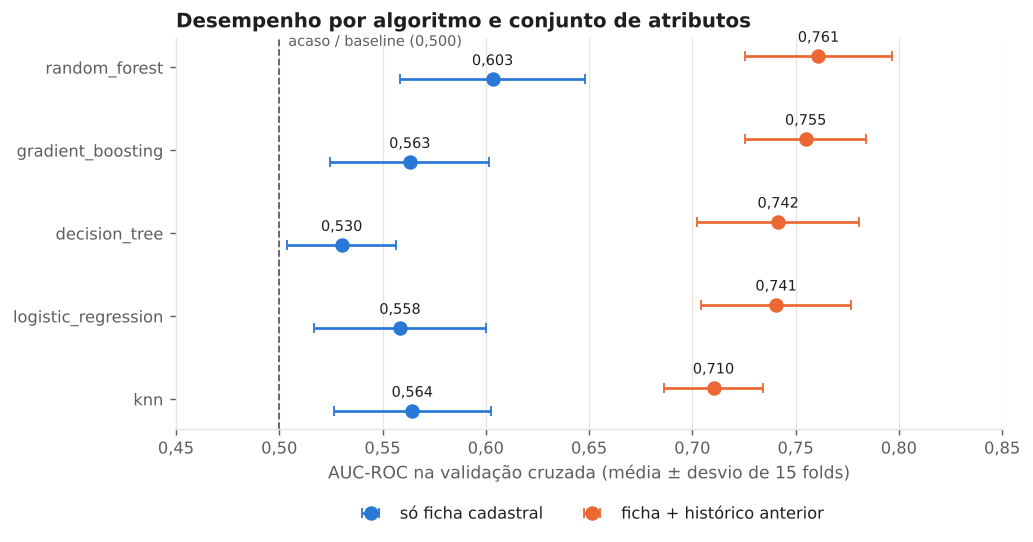

In [7]:
ordem = (cv_base[(cv_base["atributos"] == "cadastro_historico") & (cv_base["modelo"] != "baseline")]
         .sort_values("roc_auc")["modelo"].tolist())
fig, ax = plt.subplots(figsize=(8.2, 3.9))
for desloc, (conjunto, cor, rot) in zip(
        (-0.14, 0.14),
        [("cadastro", COR_BOM, "só ficha cadastral"),
         ("cadastro_historico", COR_MAU, "ficha + histórico anterior")]):
    sub = cv_base[cv_base["atributos"] == conjunto].set_index("modelo").loc[ordem]
    y = np.arange(len(ordem)) + desloc
    ax.errorbar(sub["roc_auc"], y, xerr=sub["roc_auc_dp"], fmt="o", color=cor, ms=7, lw=1.5,
                capsize=3, label=rot)
    for xi, yi in zip(sub["roc_auc"], y):
        ax.text(xi, yi + 0.17, f"{xi:.3f}".replace(".", ","), ha="center", fontsize=8)
ax.axvline(0.5, color="#5f5e5a", lw=1, ls="--")
ax.annotate("acaso / baseline (0,500)", (0.5, len(ordem) - 1), xytext=(5, 12), textcoords="offset points",
            fontsize=8, color="#5f5e5a")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.2f}".replace(".", ","))
ax.set_yticks(np.arange(len(ordem)), ordem)
ax.set_xlabel(f"AUC-ROC na validação cruzada (média ± desvio de {CV_REPEATS * CV_FOLDS} folds)")
ax.set_title("Desempenho por algoritmo e conjunto de atributos")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
ax.grid(axis="y", visible=False)
ax.set_xlim(0.45, 0.85)
save(fig, "03_cv_modelos")
plt.show()

**Leitura.**

1. **O conjunto de atributos importa muito mais que o algoritmo.** Só com a ficha cadastral
   (azul), o melhor modelo chega a AUC 0,60 e os demais ficam entre 0,53 e 0,56, pouco acima
   do acaso. Com o histórico anterior (laranja), todos sobem para 0,71–0,76. O ganho de
   trocar os dados é de cerca de 0,16 ponto de AUC; o de trocar o algoritmo, dentro do mesmo
   conjunto, é de no máximo 0,05.
2. **A hipótese da EDA se confirma.** A ficha cadastral, sozinha, quase não distingue bons de
   maus pagadores. O que distingue é o comportamento anterior.
3. **Entre os algoritmos, os ensembles lideram por pouco.** Random Forest (0,761) e Gradient
   Boosting (0,755) na frente, árvore única e regressão logística logo atrás (0,742 e 0,741),
   KNN por último (0,710). As barras de erro (±0,03 a 0,04) se sobrepõem bastante.
4. **PR-AUC** conta a mesma história em outra escala: de 0,015 (acaso) para 0,06–0,09. O
   modelo concentra maus no topo do ranking cinco a seis vezes mais que o acaso, mas está
   longe de identificá-los um a um.

## 5. Ajuste de hiperparâmetros

Busca aleatória (`RandomizedSearchCV`) para os três modelos que competem pela liderança,
no conjunto `cadastro_historico`, usando os mesmos folds agrupados e AUC-ROC como critério.
As grades estão em `PARAM_GRIDS` (`src/models.py`): força da regularização na logística;
tamanho mínimo de folha, profundidade e atributos por divisão na floresta; taxa de
aprendizado, número e profundidade das árvores e regularização no boosting.

In [8]:
feats = FEATURE_SETS["cadastro_historico"]
candidatos = get_models(feats)
n_iter = {"logistic_regression": 6, "gradient_boosting": 20, "random_forest": 8}
melhores, ajustados = {}, {}
for nome in n_iter:
    t0 = time.time()
    busca = tune(candidatos[nome], PARAM_GRIDS[nome], train, feats, n_iter=n_iter[nome],
                 random_state=RANDOM_STATE)
    melhores[nome] = busca.best_params_
    ajustados[nome] = clone(candidatos[nome]).set_params(**busca.best_params_)
    res = pd.DataFrame(busca.cv_results_)["mean_test_score"]
    print(f"{nome}: {len(res)} combinações em {time.time() - t0:.0f}s | AUC pior {res.min():.3f} · "
          f"mediana {res.median():.3f} · melhor {res.max():.3f}")
    print("   melhor:", busca.best_params_)
json.dump(melhores, open(METRICS / "melhores_hiperparametros.json", "w"), indent=2)

logistic_regression: 6 combinações em 22s | AUC pior 0.743 · mediana 0.749 · melhor 0.754
   melhor: {'clf__C': 0.003}
gradient_boosting: 20 combinações em 114s | AUC pior 0.740 · mediana 0.753 · melhor 0.758
   melhor: {'clf__min_samples_leaf': 50, 'clf__max_iter': 150, 'clf__max_depth': 3, 'clf__learning_rate': 0.02, 'clf__l2_regularization': 10.0}
random_forest: 8 combinações em 112s | AUC pior 0.742 · mediana 0.760 · melhor 0.765
   melhor: {'clf__min_samples_leaf': 20, 'clf__max_features': 'sqrt', 'clf__max_depth': None}


**Leitura.** O ajuste rende pouco, e isso é uma informação em si: dentro de cada algoritmo, a
distância entre a pior e a melhor combinação é de 0,01 a 0,02 ponto de AUC, menor que o
ruído entre folds. A logística melhora com regularização bem mais forte (`C = 0,003`), o que
faz sentido com atributos tão correlacionados entre si. Na Random Forest a melhor combinação
é a configuração de partida (folhas com pelo menos 20 contas). No boosting vence a versão
mais conservadora (taxa de aprendizado baixa, regularização alta). Com 296 maus no treino,
modelos mais simples e regularizados generalizam melhor.

## 6. Comparação

In [9]:
finais = {}
for nome, modelo in ajustados.items():
    oof[("cadastro_historico", nome + "_ajustado")], tab = cross_validate_model(modelo, train, feats)
    cv_folds[("cadastro_historico", nome + "_ajustado")] = tab
    finais[nome] = {"roc_auc": tab["roc_auc"].mean(), "roc_auc_dp": tab["roc_auc"].std(),
                    "pr_auc": tab["pr_auc"].mean(), "ks": tab["ks"].mean(),
                    "roc_auc_antes_do_ajuste": cv_folds[("cadastro_historico", nome)]["roc_auc"].mean()}
cv_final = pd.DataFrame(finais).T.sort_values("roc_auc", ascending=False)
cv_final.to_csv(METRICS / "cv_modelos_ajustados.csv")

melhor = cv_final.index[0]
ref = cv_folds[("cadastro_historico", melhor + "_ajustado")]["roc_auc"].to_numpy()
for nome in cv_final.index[1:]:
    d = ref - cv_folds[("cadastro_historico", nome + "_ajustado")]["roc_auc"].to_numpy()
    print(f"{melhor} − {nome}: diferença média de AUC {d.mean():+.3f} "
          f"(desvio {d.std(ddof=1):.3f}; {melhor} vence em {(d > 0).sum()} de {len(d)} folds)")
escolhido, regra = choose_model({n: cv_folds[("cadastro_historico", n + "_ajustado")]["roc_auc"].to_numpy()
                                 for n in cv_final.index})
regra.to_csv(METRICS / "regra_de_escolha.csv")
print(f"\nMaior AUC média: {melhor} | modelo escolhido pela regra de desempate: {escolhido}")
display(regra.round(3))
cv_final.round(3)

random_forest − gradient_boosting: diferença média de AUC +0.006 (desvio 0.012; random_forest vence em 10 de 15 folds)
random_forest − logistic_regression: diferença média de AUC +0.010 (desvio 0.017; random_forest vence em 11 de 15 folds)

Maior AUC média: random_forest | modelo escolhido pela regra de desempate: logistic_regression


,roc_auc_media,diferenca_para_o_melhor,desvio_da_diferenca,empata_com_o_melhor,posicao_em_simplicidade
modelo,,,,,
logistic_regression,0.751,0.010,0.017,True,0
gradient_boosting,0.755,0.006,0.012,True,3
random_forest,0.761,0.000,0.000,True,4


,roc_auc,roc_auc_dp,pr_auc,ks,roc_auc_antes_do_ajuste
random_forest,0.761,0.036,0.088,0.412,0.761
gradient_boosting,0.755,0.033,0.075,0.422,0.755
logistic_regression,0.751,0.035,0.090,0.423,0.741


**Leitura.** Depois do ajuste os três ficam praticamente empatados: Random Forest 0,761,
Gradient Boosting 0,755 e regressão logística 0,751. A diferença pareada, fold a fold, é de
+0,006 e +0,010 a favor da Random Forest, sempre **menor que o desvio da própria diferença**
(0,012 e 0,017): está dentro da variação normal entre rodadas.

**Regra de escolha** (`choose_model`, em `src/models.py`): parte-se do modelo de maior AUC
média; se um modelo mais simples empata com ele (diferença média menor que o desvio da
diferença), fica o mais simples. Em crédito, explicar cada decisão tem valor de negócio e
regulatório: com a regressão logística, cada recusa pode ser justificada pelos pesos dos
fatores. A regra usa apenas a validação cruzada do treino; o teste não entra na escolha.

**Modelo escolhido: regressão logística** (ficha + histórico, `C = 0,003`). O custo dessa
escolha é dito com clareza: a Random Forest teve AUC média um pouco maior e venceu em 11 dos
15 folds. Como a margem está dentro do ruído, prevaleceu a explicabilidade. Os dois modelos
são salvos e avaliados no teste.

## 7. Limiar de decisão e treino final

O modelo devolve um escore de risco entre 0 e 1; para aprovar ou reprovar é preciso um
limiar. Ele é escolhido com as predições **out-of-fold do treino** (cada conta recebe o
escore de um modelo que não a viu), nunca com o teste.

O escore não é uma probabilidade calibrada: por causa dos pesos de classe, um escore de 0,5
não significa 50% de chance de atraso. Ele serve para **ordenar** os pedidos por risco.

In [10]:
p_oof = oof[("cadastro_historico", escolhido + "_ajustado")]
limiar_f1 = best_threshold(y_train, p_oof, beta=1)
limiar_f2 = best_threshold(y_train, p_oof, beta=2)
linhas = []
for rot, lim in [("máximo F1", limiar_f1), ("máximo F2 (recall pesa mais)", limiar_f2),
                 ("0,50 (padrão)", 0.5)]:
    linhas.append({"critério": rot, "limiar": lim, "% reprovados": 100 * (p_oof >= lim).mean(),
                   **score(y_train, (p_oof >= lim).astype(int))})
display(pd.DataFrame(linhas).set_index("critério").round(3))
policy_table(y_train, p_oof).round(2)

,limiar,% reprovados,accuracy,balanced_accuracy,precision,recall,f1
critério,,,,,,,
máximo F1,0.768,1.308,0.976,0.564,0.160,0.139,0.148
máximo F2 (recall pesa mais),0.708,4.341,0.949,0.601,0.084,0.243,0.125
"0,50 (padrão)",0.500,34.490,0.662,0.695,0.032,0.730,0.061


,reprovados_pct,pedidos_reprovados,maus_barrados,maus_barrados_pct,inadimplencia_reprovados_pct,inadimplencia_aprovados_pct,bons_reprovados_por_mau
0,2.0,393,48,16.22,12.21,1.29,7.19
1,5.0,983,74,25.00,7.53,1.19,12.28
2,10.0,1965,103,34.80,5.24,1.09,18.08
3,20.0,3930,160,54.05,4.07,0.87,23.56
4,30.0,5896,195,65.88,3.31,0.73,29.24


**Leitura.**

- O limiar que maximiza o **F1** (0,768) reprova 1,3% dos pedidos, barra 14% dos maus e
  acerta 16% das reprovações. É o limiar de referência usado nas tabelas de métricas.
- O de **máximo F2**, que dá mais peso ao recall, reprova 4,3% e barra 24% dos maus, com
  precisão de 8%. O **padrão de 0,50** não serve aqui: por causa dos pesos de classe, ele
  reprovaria 34% dos pedidos.
- A acurácia não informa nada: aprovar todo mundo daria 98,5%.

A segunda tabela traduz o escore em política de crédito, ainda nas predições out-of-fold do
treino. Reprovando os **5% de maior risco**, barram-se **25% dos maus** e a inadimplência
entre os aprovados cai de 1,51% para 1,19%. Reprovando 20%, barram-se 54%. A última coluna é
o custo: quantos bons pagadores são recusados para cada mau barrado (7 no corte de 2%, 12 no
de 5%, 24 no de 20%). Nesse trecho do ranking, a Random Forest foi um pouco melhor no treino
(30% dos maus no corte de 5%); no teste, os dois empatam (notebook 04).

In [11]:
# Treino final em TODO o conjunto de treino. O teste continua intocado até o notebook 04.
feats_cad = FEATURE_SETS["cadastro"]
entregas = {
    escolhido: (ajustados[escolhido], feats, ("cadastro_historico", escolhido + "_ajustado")),
    **{n: (ajustados[n], feats, ("cadastro_historico", n + "_ajustado")) for n in ajustados if n != escolhido},
    "decision_tree": (candidatos["decision_tree"], feats, ("cadastro_historico", "decision_tree")),
    "knn": (candidatos["knn"], feats, ("cadastro_historico", "knn")),
    "random_forest_so_cadastro": (get_models(feats_cad)["random_forest"], feats_cad, ("cadastro", "random_forest")),
}
MODELS.mkdir(parents=True, exist_ok=True)
meta = {"modelo_escolhido": escolhido, "random_state": RANDOM_STATE, "modelos": {}}
for nome, (modelo, cols, chave) in entregas.items():
    ajustado = clone(modelo).fit(train[cols], train[TARGET])
    joblib.dump(ajustado, MODELS / f"{nome}.joblib")
    meta["modelos"][nome] = {
        "atributos": cols,
        "limiar_f1": best_threshold(y_train, oof[chave], beta=1),
        "limiar_f2": best_threshold(y_train, oof[chave], beta=2),
        "cv_roc_auc": float(cv_folds[chave]["roc_auc"].mean()),
        "cv_roc_auc_dp": float(cv_folds[chave]["roc_auc"].std()),
        "cv_pr_auc": float(cv_folds[chave]["pr_auc"].mean()),
        "cv_ks": float(cv_folds[chave]["ks"].mean()),
    }
json.dump(meta, open(METRICS / "modelos_treinados.json", "w"), indent=2)
pd.DataFrame(meta["modelos"]).T.drop(columns="atributos").astype(float).round(4)

,limiar_f1,limiar_f2,cv_roc_auc,cv_roc_auc_dp,cv_pr_auc,cv_ks
logistic_regression,0.7676,0.7085,0.7513,0.0347,0.0903,0.4233
gradient_boosting,0.6895,0.6554,0.7549,0.0334,0.0746,0.4217
random_forest,0.5720,0.4534,0.7611,0.0357,0.0882,0.4119
decision_tree,0.8847,0.8847,0.7416,0.0391,0.0620,0.3860
knn,0.0596,0.0361,0.7103,0.0240,0.0769,0.3411
random_forest_so_cadastro,0.4652,0.3768,0.6033,0.0449,0.0606,0.2239


Os modelos foram treinados no conjunto de treino inteiro e salvos em `results/models/`
(fora do Git; são regenerados por este notebook). Limiares e métricas de validação ficam em
`results/metrics/modelos_treinados.json`.

## 8. Leitura

1. **Validação honesta muda o resultado.** Com split aleatório, o mesmo modelo marca AUC de
   0,76 a 0,82; agrupando por cliente, 0,60. Os números deste projeto são os que devem se
   repetir com clientes que o modelo nunca viu.
2. **Os dados pesam mais que o algoritmo.** A ficha cadastral sozinha leva a AUC de 0,60 no
   melhor caso. Acrescentar o histórico anterior do cliente leva a 0,76.
3. **A regressão logística foi a escolhida.** Random Forest (0,761), Gradient Boosting (0,755)
   e regressão logística (0,751 ± 0,035) empatam dentro do ruído da validação cruzada; pela
   regra de desempate, fica o modelo mais simples e explicável.
4. **O modelo ordena risco, não adivinha inadimplentes.** Ele concentra maus no topo do
   ranking (os 5% de maior risco reúnem 25% dos maus no treino), mas não os identifica um a um.

O notebook 04 confere esses números no conjunto de teste e interpreta o modelo.